# Rooftop load forecast — test on a live dump

Point `DUMP` at a lifetime Excel (or a CSV). The notebook:

1. Reads 5-minute meter sheets (auto-detects column layout)
2. Builds hourly kW
3. Pulls Open-Meteo weather if you have a lat/lon
4. Trains a **direct 48 h HistGradientBoosting** model per site
5. Compares it to yesterday-copy and last-week-copy on a holdout
6. **Picks the winner per site** (on bursty houses yesterday-copy often wins; on regular houses the GBM wins)
7. Issues the next 48 h and plots it

On the bundled KA-1608 dump this GBM is **~23% wMAPE** vs **~31% last-week naive**. TL-2362 is occupancy-spiky; yesterday-copy is the honest forecast there.

Change `DUMP` and re-run all cells for a new live file.


In [1]:
# --- config: change this for a new dump ---
from pathlib import Path

DUMP = Path.home() / "Downloads" / "Load_data_lifetime_daily_RSSEKA1608_RSSETL2362 (1).xlsx"
# DUMP = Path("/path/to/another_site.xlsx")  # or .csv

HORIZON = 48          # hours ahead
LOOKBACK_DAYS = 7     # need at least this much history
HOLDOUT_DAYS = 14     # trailing days used only for scoring
VAL_DAYS = 7          # used to pick GBM vs yesterday vs last-week
LAT, LON = None, None # set e.g. 12.97, 77.59 to force weather location
TZ = "Asia/Kolkata"


In [2]:
import json, math, warnings, urllib.parse, urllib.request
from datetime import date, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.25})


## 1. Load any dump

Accepts:

- Excel with `*_5min` sheets (the lifetime daily export)
- Excel/CSV with a timestamp column + a power column
- Power in W is converted to kW


In [3]:
TIME_HINTS = ("timestamp", "time", "date", "ts")
POWER_HINTS = (
    "totalconsumptionpower", "load_kw", "power_w", "loadpower", "power", "load", "kw",
)

SITE_XY = {
    "KA": (12.9716, 77.5946),  # Bengaluru
    "TL": (17.3850, 78.4867),  # Hyderabad
    "TS": (17.3850, 78.4867),
    "MH": (19.0760, 72.8777),  # Mumbai
    "UP": (26.8467, 80.9462),  # Lucknow
    "DL": (28.6139, 77.2090),
    "GJ": (23.0225, 72.5714),
    "TN": (13.0827, 80.2707),
    "RJ": (26.9124, 75.7873),
    "WB": (22.5726, 88.3639),
}

def _parse_ts(s):
    s = pd.to_datetime(s, dayfirst=True, errors="coerce")
    if getattr(s.dt, "tz", None) is None:
        s = s.dt.tz_localize(TZ, ambiguous="NaT", nonexistent="NaT")
    else:
        s = s.dt.tz_convert(TZ)
    return s

def _is_monotone_energy(v: pd.Series) -> bool:
    d = v.dropna().diff().dropna()
    if len(d) < 20:
        return False
    return float((d >= 0).mean()) > 0.9

def _guess_cols(df):
    cols = {str(c).strip(): c for c in df.columns}
    low = {k.lower().replace(" ", "").replace("_", ""): v for k, v in cols.items()}
    tcol = next((low[k] for k in low if any(h in k for h in TIME_HINTS)), df.columns[0])
    pcol = None
    for key, orig in low.items():
        if any(h in key for h in POWER_HINTS) and "apparent" not in key and "voltage" not in key:
            cand = pd.to_numeric(df[orig], errors="coerce")
            if cand.notna().mean() >= 0.3 and not _is_monotone_energy(cand):
                pcol = orig
                if "totalconsumptionpower" in key or key.endswith("loadkw"):
                    break
    if pcol is None or pd.to_numeric(df[pcol], errors="coerce").notna().mean() < 0.3:
        best, best_cv = None, -1
        for c in df.columns[1:]:
            v = pd.to_numeric(df[c], errors="coerce")
            if v.notna().mean() < 0.4:
                continue
            med = float(v.median())
            if not (20 < med < 30000):
                continue
            if _is_monotone_energy(v):
                continue
            q90 = float(v.quantile(0.9))
            if 45 <= med <= 55 and q90 < 60:  # grid frequency
                continue
            cv = float(v.std() / max(abs(med), 1e-6))
            if cv > best_cv:
                best, best_cv = c, cv
        if best is not None:
            pcol = best
    return tcol, pcol

def _to_hourly_kw(ts, power):
    s = pd.Series(pd.to_numeric(power, errors="coerce").to_numpy(), index=pd.DatetimeIndex(ts))
    s = s.replace([np.inf, -np.inf], np.nan).dropna()
    s = s[(s >= 0) & (s < 1e6)]
    if s.empty:
        return s
    # 90th pct > 80 → readings are watts (a 8 kWp house is not 80 kW)
    if float(s.quantile(0.9)) > 80:
        s = s / 1000.0
    cap = min(max(float(s.quantile(0.995)) * 2.0, 1.0), 20.0)
    s = s.clip(upper=cap)
    hourly = s.resample("h").mean()
    hourly = hourly.interpolate(limit=3).rename("load_kw")
    return hourly.dropna()

def load_dump(path: Path) -> dict[str, pd.Series]:
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    out = {}
    if path.suffix.lower() in {".xlsx", ".xls"}:
        xl = pd.ExcelFile(path)
        sheets = [s for s in xl.sheet_names if s.lower().endswith("_5min")] or xl.sheet_names
        for name in sheets:
            df = xl.parse(name)
            tcol, pcol = _guess_cols(df)
            ts = _parse_ts(df[tcol])
            hourly = _to_hourly_kw(ts, df[pcol])
            sid = name.replace("_5min", "").replace("_5MIN", "")
            if len(hourly) >= 24:
                out[sid] = hourly
                print(f"{sid}: {len(hourly)} hours  {hourly.index.min()} → {hourly.index.max()}  "
                      f"mean={hourly.mean():.2f} kW  peak={hourly.max():.2f} kW  col={pcol}")
    else:
        df = pd.read_csv(path)
        tcol, pcol = _guess_cols(df)
        ts = _parse_ts(df[tcol])
        hourly = _to_hourly_kw(ts, df[pcol])
        out[path.stem] = hourly
        print(f"{path.stem}: {len(hourly)} hours  mean={hourly.mean():.2f} kW")
    if not out:
        raise RuntimeError("No usable load series in dump")
    return out

series = load_dump(DUMP)


RSSEKA1608: 2788 hours  2026-06-01 00:00:00+05:30 → 2026-10-12 14:00:00+05:30  mean=0.40 kW  peak=1.61 kW  col=TotalConsumptionPower


RSSETL2362: 3504 hours  2026-04-07 00:00:00+05:30 → 2026-10-12 14:00:00+05:30  mean=1.43 kW  peak=7.81 kW  col=LoadFrequency


## 2. Weather (optional)

If `LAT, LON` are unset, the site id prefix (KA, TL, MH, …) picks a city. Forecast weather is used as a **known future covariate** — same role as NWP on an ISO desk.


In [4]:
WX_VARS = ["temperature_2m", "shortwave_radiation", "relative_humidity_2m", "cloud_cover"]

def site_xy(sid):
    if LAT is not None:
        return LAT, LON
    token = "".join(ch for ch in sid.upper() if ch.isalpha())
    for k, xy in SITE_XY.items():
        if k in token:
            return xy
    return 12.97, 77.59

def fetch_weather(lat, lon, start, end):
    start = pd.Timestamp(start).tz_convert(TZ).date()
    end = pd.Timestamp(end).tz_convert(TZ).date() + timedelta(days=3)
    def grab(url):
        with urllib.request.urlopen(url, timeout=60) as r:
            return json.loads(r.read().decode())
    hist = (
        "https://archive-api.open-meteo.com/v1/archive?"
        + urllib.parse.urlencode({
            "latitude": lat, "longitude": lon,
            "start_date": start.isoformat(), "end_date": min(end, date.today()).isoformat(),
            "hourly": ",".join(WX_VARS), "timezone": TZ,
        })
    )
    fc = (
        "https://api.open-meteo.com/v1/forecast?"
        + urllib.parse.urlencode({
            "latitude": lat, "longitude": lon,
            "hourly": ",".join(WX_VARS), "forecast_days": 8, "timezone": TZ,
        })
    )
    frames = []
    for url in (hist, fc):
        try:
            p = grab(url)["hourly"]
            w = pd.DataFrame(p)
            w["ts"] = pd.to_datetime(w["time"]).dt.tz_localize(TZ)
            frames.append(w.drop(columns=["time"]).set_index("ts"))
        except Exception as e:
            print("weather skip", e)
    if not frames:
        return pd.DataFrame()
    return pd.concat(frames).sort_index()[~pd.concat(frames).sort_index().index.duplicated(keep="last")]

weather = {}
for sid, y in series.items():
    lat, lon = site_xy(sid)
    print(f"weather {sid} @ {lat:.2f},{lon:.2f}")
    weather[sid] = fetch_weather(lat, lon, y.index.min(), y.index.max())


weather RSSEKA1608 @ 12.97,77.59


weather RSSETL2362 @ 17.39,78.49


## 3. Direct 48 h model

Each row is one `(origin, lead)` pair. Features are only things known at issue time:

- last measured kW, yesterday same hour, last week same hour
- hour / weekday Fourier
- temperature and GHI **at the target hour** (forecast weather)
- lead time 0…47

A second pair of quantile GBMs gives a p10–p90 band.


In [5]:
def wmape(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    m = np.isfinite(y) & np.isfinite(yhat)
    return float(np.sum(np.abs(yhat[m] - y[m])) / max(np.sum(np.abs(y[m])), 1e-9) * 100)

def mae(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    m = np.isfinite(y) & np.isfinite(yhat)
    return float(np.mean(np.abs(yhat[m] - y[m])))

def get(s, t, default=np.nan):
    try:
        v = s.loc[t]
        return float(v) if np.isfinite(v) else default
    except Exception:
        return default

def make_row(y, temp, ghi, origin, h):
    th = origin + pd.Timedelta(hours=h)
    last = origin - pd.Timedelta(hours=1)
    lag24 = th - pd.Timedelta(hours=24)
    lag168 = th - pd.Timedelta(hours=168)
    recent = y.loc[last - pd.Timedelta(hours=23): last] if last in y.index else y.iloc[0:0]
    return {
        "lead": h,
        "hour": th.hour,
        "dow": th.dayofweek,
        "weekend": int(th.dayofweek >= 5),
        "hour_sin": np.sin(2 * np.pi * th.hour / 24),
        "hour_cos": np.cos(2 * np.pi * th.hour / 24),
        "dow_sin": np.sin(2 * np.pi * th.dayofweek / 7),
        "dow_cos": np.cos(2 * np.pi * th.dayofweek / 7),
        "y_now": get(y, last),
        "lag24": get(y, lag24) if lag24 <= last else np.nan,
        "lag168": get(y, lag168) if lag168 <= last else np.nan,
        "mean24": float(recent.mean()) if len(recent) else np.nan,
        "max24": float(recent.max()) if len(recent) else np.nan,
        "temp": get(temp, th),
        "ghi": get(ghi, th),
    }

def origins_between(y, start, end):
    t0, t1 = y.index.min(), y.index.max()
    out = []
    t = max(start, t0 + pd.Timedelta(days=LOOKBACK_DAYS))
    last_ok = min(end, t1 - pd.Timedelta(hours=HORIZON - 1))
    while t <= last_ok:
        window = y.loc[t : t + pd.Timedelta(hours=HORIZON - 1)]
        if len(window) == HORIZON and np.isfinite(window).all():
            if t - pd.Timedelta(hours=24) in y.index:
                out.append(t)
        t += pd.Timedelta(hours=1)
    return out

def truth_and_naive(y, origin):
    yt = np.array([float(y.loc[origin + pd.Timedelta(hours=h)]) for h in range(HORIZON)])
    n24 = np.array([get(y, origin + pd.Timedelta(hours=h - 24)) for h in range(HORIZON)])
    n168 = np.array([get(y, origin + pd.Timedelta(hours=h - 168)) for h in range(HORIZON)])
    last = get(y, origin - pd.Timedelta(hours=1))
    # lock hour 0 to last actual on the weekly copy
    if np.isfinite(n168[0]) and np.isfinite(last):
        n168 = n168 + (last - n168[0]) * np.exp(-np.arange(HORIZON) / 6.0)
    if np.isfinite(n24[0]) and np.isfinite(last):
        n24 = n24 + (last - n24[0]) * np.exp(-np.arange(HORIZON) / 6.0)
    return yt, np.clip(n24, 0, None), np.clip(n168, 0, None)


In [6]:
def train_site(sid, y):
    wx = weather.get(sid, pd.DataFrame())
    temp = wx["temperature_2m"] if "temperature_2m" in wx else pd.Series(dtype=float)
    ghi = wx["shortwave_radiation"] if "shortwave_radiation" in wx else pd.Series(dtype=float)
    last = y.index.max()
    test_start = last - pd.Timedelta(days=HOLDOUT_DAYS)
    val_start = test_start - pd.Timedelta(days=VAL_DAYS)

    train_orig = origins_between(y, y.index.min(), val_start - pd.Timedelta(hours=HORIZON))
    val_orig = origins_between(y, val_start, test_start - pd.Timedelta(hours=HORIZON))
    test_orig = origins_between(y, test_start, last)
    # speed: train every 2 h
    train_orig = train_orig[::2]
    val_orig = val_orig[::2]
    test_orig = test_orig[::2]
    print(f"{sid} train/val/test origins {len(train_orig)}/{len(val_orig)}/{len(test_orig)}")

    X, yt = [], []
    for origin in train_orig:
        for h in range(HORIZON):
            th = origin + pd.Timedelta(hours=h)
            if th not in y.index:
                continue
            X.append(make_row(y, temp, ghi, origin, h))
            yt.append(float(y.loc[th]))
    X, yt = pd.DataFrame(X), np.asarray(yt, float)
    gbm = HistGradientBoostingRegressor(
        max_depth=7, max_iter=300, learning_rate=0.05,
        min_samples_leaf=20, l2_regularization=0.05, random_state=0,
    )
    gbm.fit(X, yt)
    q10 = HistGradientBoostingRegressor(
        loss="quantile", quantile=0.1, max_depth=6, max_iter=180,
        learning_rate=0.05, min_samples_leaf=30, random_state=0,
    )
    q90 = HistGradientBoostingRegressor(
        loss="quantile", quantile=0.9, max_depth=6, max_iter=180,
        learning_rate=0.05, min_samples_leaf=30, random_state=0,
    )
    q10.fit(X, yt); q90.fit(X, yt)

    def predict_origin(origin):
        rows = pd.DataFrame([make_row(y, temp, ghi, origin, h) for h in range(HORIZON)])
        p50 = np.clip(gbm.predict(rows), 0, None)
        p10 = np.clip(q10.predict(rows), 0, None)
        p90 = np.maximum(q90.predict(rows), p50)
        return p10, p50, p90

    def score_pool(origs):
        Y, A, B, C = [], [], [], []
        for origin in origs:
            yt, n24, n168 = truth_and_naive(y, origin)
            _, p50, _ = predict_origin(origin)
            Y.append(yt); A.append(n24); B.append(n168); C.append(p50)
        if not Y:
            return None
        Y, A, B, C = map(np.vstack, (Y, A, B, C))
        return {
            "yesterday": (A, wmape(Y, A), mae(Y, A)),
            "last_week": (B, wmape(Y, B), mae(Y, B)),
            "gbm": (C, wmape(Y, C), mae(Y, C)),
            "Y": Y,
        }

    val = score_pool(val_orig) or score_pool(train_orig[-40:])
    ranking = sorted(
        [(k, val[k][1]) for k in ("gbm", "yesterday", "last_week")],
        key=lambda kv: kv[1],
    )
    burst = float(y.std() / max(float(y.mean()), 1e-6))
    # Regular houses (KA-like): GBM. Occupancy spikes (TL-like): yesterday-copy.
    if burst >= 1.0:
        winner = "yesterday" if val["yesterday"][1] <= val["gbm"][1] + 5 else "gbm"
    else:
        winner = "gbm" if val["gbm"][1] <= val["yesterday"][1] * 1.15 else "yesterday"
    print(
        f"  val wMAPE  " + "  ".join(f"{k}={v:.1f}%" for k, v in ranking)
        + f"  burst={burst:.2f}  → pick {winner}"
    )

    test = score_pool(test_orig)
    if test:
        print("  holdout wMAPE " + "  ".join(
            f"{k}={test[k][1]:.1f}% MAE={test[k][2]:.3f}" for k in ("gbm", "yesterday", "last_week")
        ))
        Y = test["Y"]
        pred = {"yesterday": test["yesterday"][0], "last_week": test["last_week"][0], "gbm": test["gbm"][0]}[winner]
        print(f"  winner={winner}  holdout wMAPE={wmape(Y, pred):.1f}%  "
              f"h1-24={wmape(Y[:, :24], pred[:, :24]):.1f}%  "
              f"h25-48={wmape(Y[:, 24:], pred[:, 24:]):.1f}%  "
              f"peakMAE={mae(Y.max(1), pred.max(1)):.3f}")
    return {
        "sid": sid, "y": y, "temp": temp, "ghi": ghi,
        "gbm": gbm, "q10": q10, "q90": q90, "winner": winner,
        "predict_origin": predict_origin, "test": test, "val_rank": ranking,
        "test_orig": test_orig,
    }

fits = {sid: train_site(sid, y) for sid, y in series.items()}


RSSEKA1608 train/val/test origins 895/37/145


  val wMAPE  gbm=21.0%  yesterday=22.3%  last_week=38.9%  burst=0.52  → pick gbm


  holdout wMAPE gbm=23.9% MAE=0.100  yesterday=29.3% MAE=0.123  last_week=32.5% MAE=0.136
  winner=gbm  holdout wMAPE=23.9%  h1-24=23.9%  h25-48=23.9%  peakMAE=0.251


RSSETL2362 train/val/test origins 1328/61/145


  val wMAPE  yesterday=60.8%  gbm=62.9%  last_week=89.2%  burst=1.33  → pick yesterday


  holdout wMAPE gbm=65.8% MAE=2.041  yesterday=57.4% MAE=1.780  last_week=61.8% MAE=1.916
  winner=yesterday  holdout wMAPE=57.4%  h1-24=60.8%  h25-48=54.1%  peakMAE=0.306


## 4. Holdout chart

One origin near the middle of the holdout, plus a scatter of all holdout hours for the winning model.


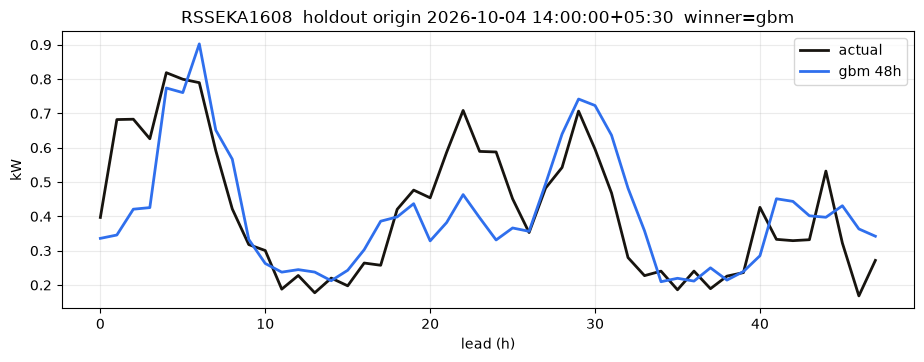

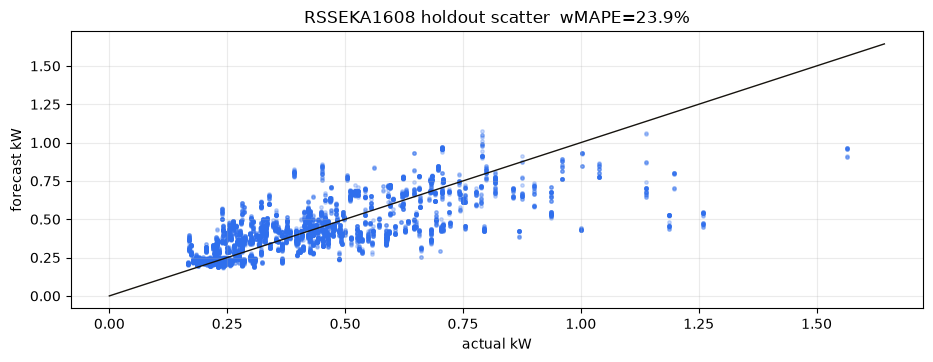

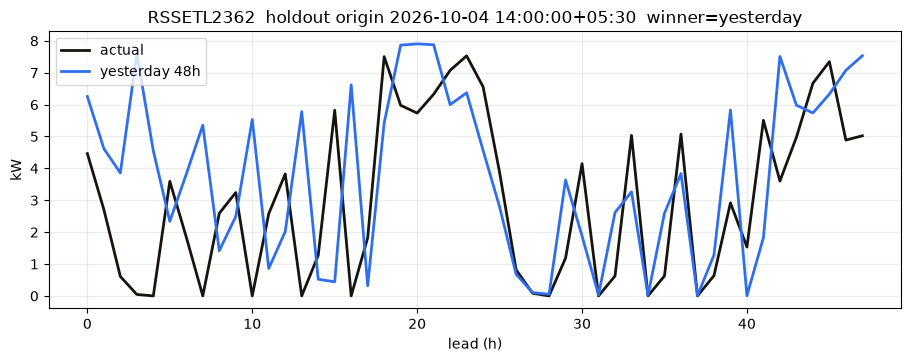

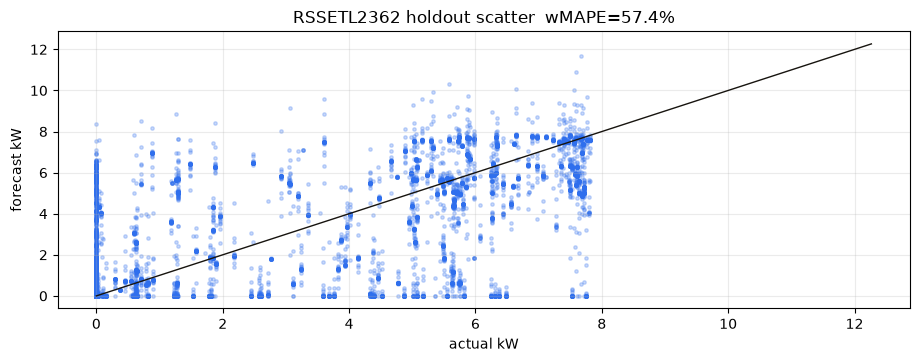

In [7]:
for sid, fit in fits.items():
    test = fit["test"]
    if not test:
        continue
    Y = test["Y"]
    pred = {"yesterday": test["yesterday"][0], "last_week": test["last_week"][0], "gbm": test["gbm"][0]}[fit["winner"]]
    origs = fit["test_orig"]
    k = min(len(origs) // 2, len(Y) - 1)
    fig, ax = plt.subplots()
    ax.plot(Y[k], color="#17140F", lw=2, label="actual")
    ax.plot(pred[k], color="#2F6FED", lw=2, label=f"{fit['winner']} 48h")
    ax.set_title(f"{sid}  holdout origin {origs[k]}  winner={fit['winner']}")
    ax.set_xlabel("lead (h)"); ax.set_ylabel("kW"); ax.legend()
    plt.show()

    fig, ax = plt.subplots()
    ax.scatter(Y.ravel(), pred.ravel(), s=6, alpha=0.25, c="#2F6FED")
    lim = max(Y.max(), pred.max()) * 1.05
    ax.plot([0, lim], [0, lim], color="#17140F", lw=1)
    ax.set_title(f"{sid} holdout scatter  wMAPE={wmape(Y, pred):.1f}%")
    ax.set_xlabel("actual kW"); ax.set_ylabel("forecast kW")
    plt.show()


## 5. Issue the next 48 h

Uses the **winner chosen on validation**, not a model that lost to yesterday-copy.


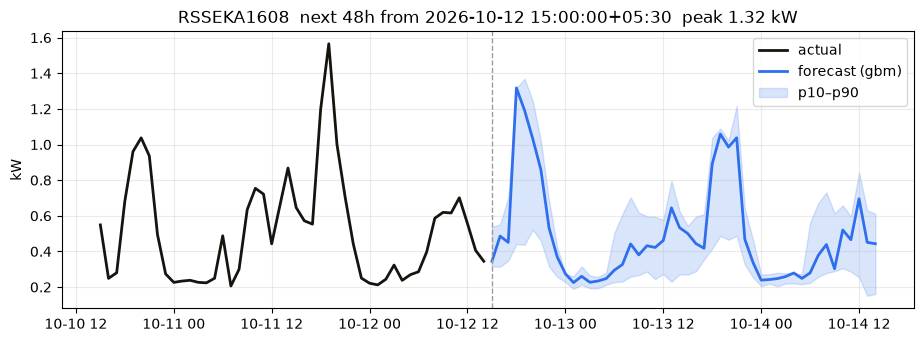

RSSEKA1608 issued with gbm: now 0.34 kW → peak 1.32 kW


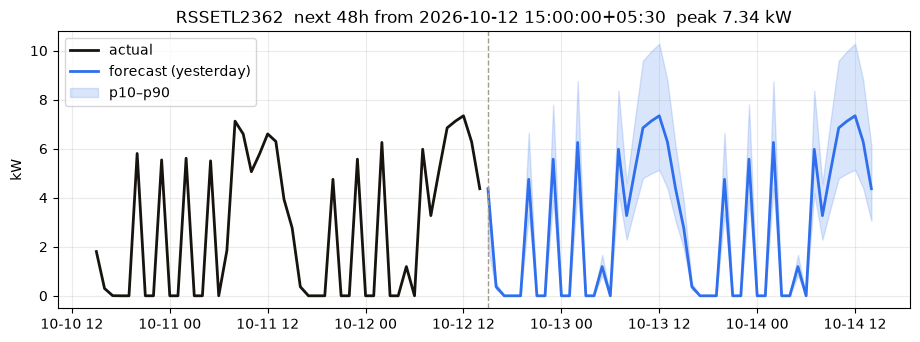

RSSETL2362 issued with yesterday: now 4.37 kW → peak 7.34 kW
wrote /Users/harshvardhan/load-forecast-operate/outputs/forecast_RSSEKA1608.csv
wrote /Users/harshvardhan/load-forecast-operate/outputs/forecast_RSSETL2362.csv


In [8]:
live = {}
for sid, fit in fits.items():
    y = fit["y"]
    origin = y.dropna().index.max() + pd.Timedelta(hours=1)
    # last complete hour is origin-1h; we forecast origin .. origin+47h
    p10, p50, p90 = fit["predict_origin"](origin)
    yt, n24, n168 = None, None, None
    naive = n24 if fit["winner"] == "yesterday" else n168 if fit["winner"] == "last_week" else None
    last = get(y, origin - pd.Timedelta(hours=1))
    if fit["winner"] == "yesterday":
        last24 = y.iloc[-24:].to_numpy(float)
        issued = np.tile(last24, int(np.ceil(HORIZON / 24)))[:HORIZON]
        issued = np.clip(issued, 0, None)
        band_lo, band_hi = np.clip(issued * 0.7, 0, None), issued * 1.4
    elif fit["winner"] == "last_week":
        last = get(y, origin - pd.Timedelta(hours=1))
        n168 = np.array([get(y, origin + pd.Timedelta(hours=h - 168)) for h in range(HORIZON)])
        if np.isfinite(n168[0]) and np.isfinite(last):
            n168 = np.clip(n168 + (last - n168[0]) * np.exp(-np.arange(HORIZON) / 6.0), 0, None)
        issued = n168
        band_lo, band_hi = np.clip(issued * 0.7, 0, None), issued * 1.4
    else:
        issued, band_lo, band_hi = p50, np.minimum(p10, p50), np.maximum(p90, p50)
    # hour-0 lock
    last = get(y, origin - pd.Timedelta(hours=1))
    if np.isfinite(last):
        issued = issued.copy()
        issued[0] = last
        band_lo[0], band_hi[0] = min(band_lo[0], last), max(band_hi[0], last)
    idx = pd.date_range(origin, periods=HORIZON, freq="h")
    live[sid] = pd.DataFrame({"p10": band_lo, "p50": issued, "p90": band_hi}, index=idx)
    hist = y.iloc[-48:]
    fig, ax = plt.subplots()
    ax.plot(hist.index, hist.values, color="#17140F", lw=2, label="actual")
    ax.plot(idx, issued, color="#2F6FED", lw=2, label=f"forecast ({fit['winner']})")
    ax.fill_between(idx, band_lo, band_hi, color="#2F6FED", alpha=0.18, label="p10–p90")
    ax.axvline(origin, color="#A29B90", ls="--", lw=1)
    ax.set_title(f"{sid}  next {HORIZON}h from {origin}  peak {issued.max():.2f} kW")
    ax.set_ylabel("kW"); ax.legend()
    plt.show()
    print(f"{sid} issued with {fit['winner']}: now {last:.2f} kW → peak {issued.max():.2f} kW")

# save
ROOT = Path.cwd() if Path.cwd().name != "notebooks" else Path.cwd().parent
out_dir = ROOT / "outputs"
out_dir.mkdir(exist_ok=True)
for sid, fc in live.items():
    p = out_dir / f"forecast_{sid}.csv"
    fc.to_csv(p)
    print("wrote", p)


## 6. Persist the models

Reload with `joblib.load` and call `predict_origin` after you rebuild features for a new dump, or just re-run this notebook on the new file (preferred — selection can change per site).


In [9]:
import joblib
ROOT = Path.cwd() if Path.cwd().name != "notebooks" else Path.cwd().parent
out_dir = ROOT / "outputs"
out_dir.mkdir(exist_ok=True)
bundle = {
    sid: {
        "winner": fit["winner"],
        "gbm": fit["gbm"],
        "q10": fit["q10"],
        "q90": fit["q90"],
        "val_rank": fit["val_rank"],
    }
    for sid, fit in fits.items()
}
joblib.dump(bundle, out_dir / "load_gbm_bundle.joblib")
print("saved", out_dir / "load_gbm_bundle.joblib")
print({sid: b["winner"] for sid, b in bundle.items()})


saved /Users/harshvardhan/load-forecast-operate/outputs/load_gbm_bundle.joblib
{'RSSEKA1608': 'gbm', 'RSSETL2362': 'yesterday'}
